In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../outputs/figures", exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../Dataset/Telco-Customer-Churn.csv")
print("loaded")

loaded


In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[(df["tenure"] == 0) & (df["TotalCharges"].isnull()), "TotalCharges"] = 0.0
print(df["TotalCharges"].isnull().sum())   # should be 0

0


In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

# Check every categorical column for inconsistent spelling or unexpected labels
for col in df.select_dtypes(include="object").columns.drop("customerID"):
    print(f"\n{col}: {df[col].unique().tolist()}")

# Check numeric ranges
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

Duplicate rows: 0
Duplicate customerIDs: 0

gender: ['Female', 'Male']

Partner: ['Yes', 'No']

Dependents: ['No', 'Yes']

PhoneService: ['No', 'Yes']

MultipleLines: ['No phone service', 'No', 'Yes']

InternetService: ['DSL', 'Fiber optic', 'No']

OnlineSecurity: ['No', 'Yes', 'No internet service']

OnlineBackup: ['Yes', 'No', 'No internet service']

DeviceProtection: ['No', 'Yes', 'No internet service']

TechSupport: ['No', 'Yes', 'No internet service']

StreamingTV: ['No', 'Yes', 'No internet service']

StreamingMovies: ['No', 'Yes', 'No internet service']

Contract: ['Month-to-month', 'One year', 'Two year']

PaperlessBilling: ['Yes', 'No']

PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']

Churn: ['No', 'Yes']
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000 

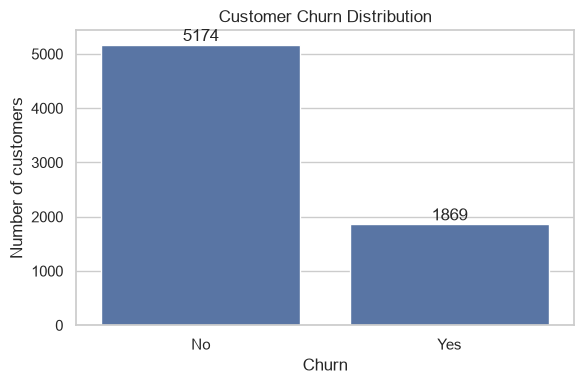

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Churn", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("../outputs/figures/01_churn_distribution.png", dpi=150)
plt.show()

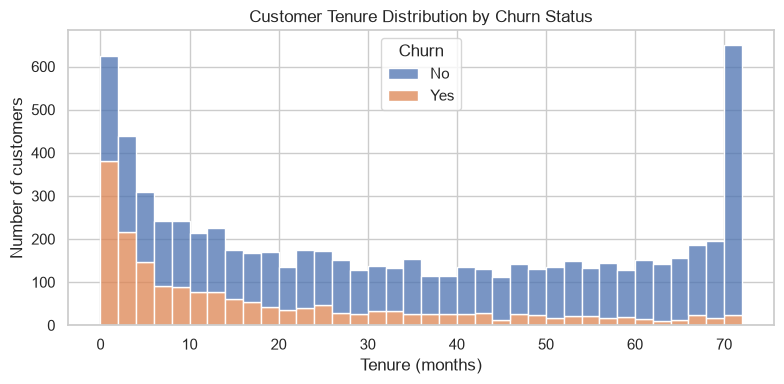

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=ax)
ax.set_title("Customer Tenure Distribution by Churn Status")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("../outputs/figures/02_tenure_distribution.png", dpi=150)
plt.show()

         Contract  ChurnRate
0  Month-to-month  42.709677
1        One year  11.269518
2        Two year   2.831858


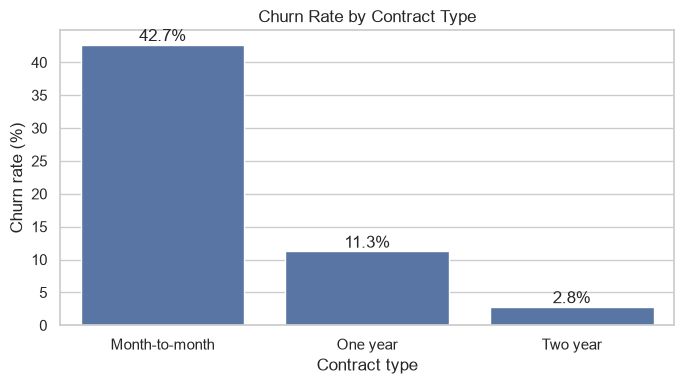

In [6]:
rate = (df.groupby("Contract")["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
          .reset_index(name="ChurnRate").sort_values("ChurnRate", ascending=False))
print(rate)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=rate, x="Contract", y="ChurnRate", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("../outputs/figures/03_churn_by_contract.png", dpi=150)
plt.show()

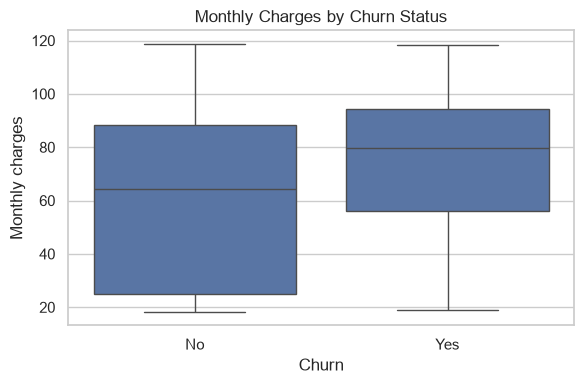

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly charges")
plt.tight_layout()
plt.savefig("../outputs/figures/04_monthly_charges_by_churn.png", dpi=150)
plt.show()

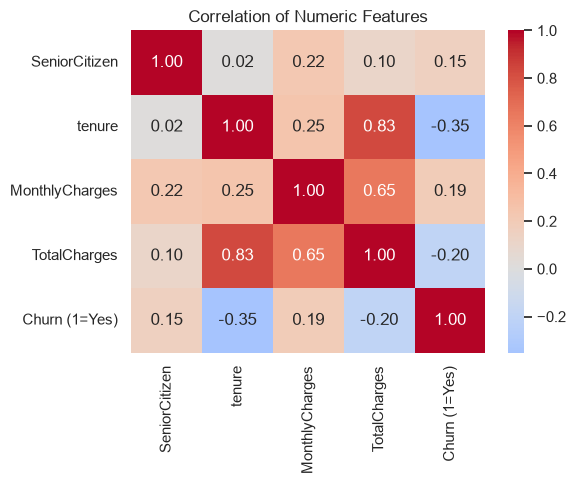

In [8]:
num = df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
num["Churn (1=Yes)"] = (df["Churn"] == "Yes").astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation of Numeric Features")
plt.tight_layout()
plt.savefig("../outputs/figures/05_correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
for col in ["InternetService", "PaymentMethod", "TechSupport", "PaperlessBilling"]:
    r = (df.groupby(col)["Churn"].apply(lambda s: s.eq("Yes").mean() * 100)
           .round(1).sort_values(ascending=False))
    print(f"\nChurn rate (%) by {col}:\n{r}")


Churn rate (%) by InternetService:
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64

Churn rate (%) by PaymentMethod:
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64

Churn rate (%) by TechSupport:
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64

Churn rate (%) by PaperlessBilling:
PaperlessBilling
Yes    33.6
No     16.3
Name: Churn, dtype: float64


In [10]:
print(pd.crosstab(df["PaymentMethod"], df["Contract"], normalize="index").round(2))
print(df.groupby("InternetService")["MonthlyCharges"].mean().round(2))

Contract                   Month-to-month  One year  Two year
PaymentMethod                                                
Bank transfer (automatic)            0.38      0.25      0.37
Credit card (automatic)              0.36      0.26      0.38
Electronic check                     0.78      0.15      0.07
Mailed check                         0.55      0.21      0.24
InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64
